# 04 — Hurdle Strategy Deep-Dive: Mixture Expectation (A) vs Hard-Gating (B)

So sánh đối đầu trực diện 16 cặp mô hình Hurdle (Strategy A vs B) trên 4 họ cơ sở và 4 tập đặc trưng; khảo sát đường cong quét ngưỡng Grid 3a.

### Project Guardrails & Execution Baseline:
- **Protocol Căn cứ:** `training_forecasting_evaluation_protocol_v1_0_21.md` và `spec_module_result_analysis_v2.md`
- **Zero Final Test Access Rule:** Chỉ nạp dữ liệu Validation (724 origins, 2018-05-01 đến 2020-04-23, H=7).
- **Purged Metrics Integrity:** Tuyệt đối không tính hoặc hiển thị CR-MAE@7, CR-Bias@7, RainDay-MAE, hay Bias.
- **Descriptive Cost Principle:** Số liệu tài nguyên chỉ dùng mô tả (PROP-07), không dùng để xếp hạng mô hình.


In [1]:
# Bootstrap root directory
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

ROOT_DIR = Path.cwd()
while not (ROOT_DIR / 'src').exists() and ROOT_DIR != ROOT_DIR.parent:
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


,base_family,feature_set,scenario_A,MAE_StratA,RMSE_StratA,scenario_B,MAE_StratB,RMSE_StratB,selected_tau_B,delta_MAE_B_minus_A,delta_RMSE_B_minus_A,advantageous_strategy
0,random_forest,F2,SC-59,3.558216,6.722383,SC-67,3.448273,7.055751,0.70,-0.109944,0.333368,Strategy B
1,random_forest,F1,SC-58,3.534246,6.690333,SC-66,3.499015,7.074338,0.70,-0.035232,0.384005,Strategy B
2,random_forest,F3,SC-60,3.561401,6.758885,SC-68,3.538493,7.183515,0.70,-0.022908,0.424630,Strategy B
3,random_forest,F0,SC-57,3.563160,6.748811,SC-65,3.585911,7.155426,0.70,0.022751,0.406615,Strategy A
4,xgboost,F0,SC-61,3.502769,6.787024,SC-69,3.603371,7.177159,0.70,0.100602,0.390135,Strategy A
5,xgboost,F1,SC-62,3.463780,6.709132,SC-70,3.583128,7.138876,0.70,0.119348,0.429744,Strategy A
6,logistic_linear,F0,SC-41,3.335640,6.691044,SC-49,3.461179,6.961072,0.65,0.125539,0.270028,Strategy A
7,xgboost,F2,SC-63,3.461069,6.731241,SC-71,3.596688,7.178935,0.70,0.135620,0.447693,Strategy A
8,logistic_linear,F2,SC-43,3.335875,6.667869,SC-51,3.490010,6.958825,0.65,0.154136,0.290956,Strategy A
9,lightgbm,F1,SC-46,3.448409,6.754807,SC-54,3.607899,7.593886,0.80,0.159490,0.839079,Strategy A


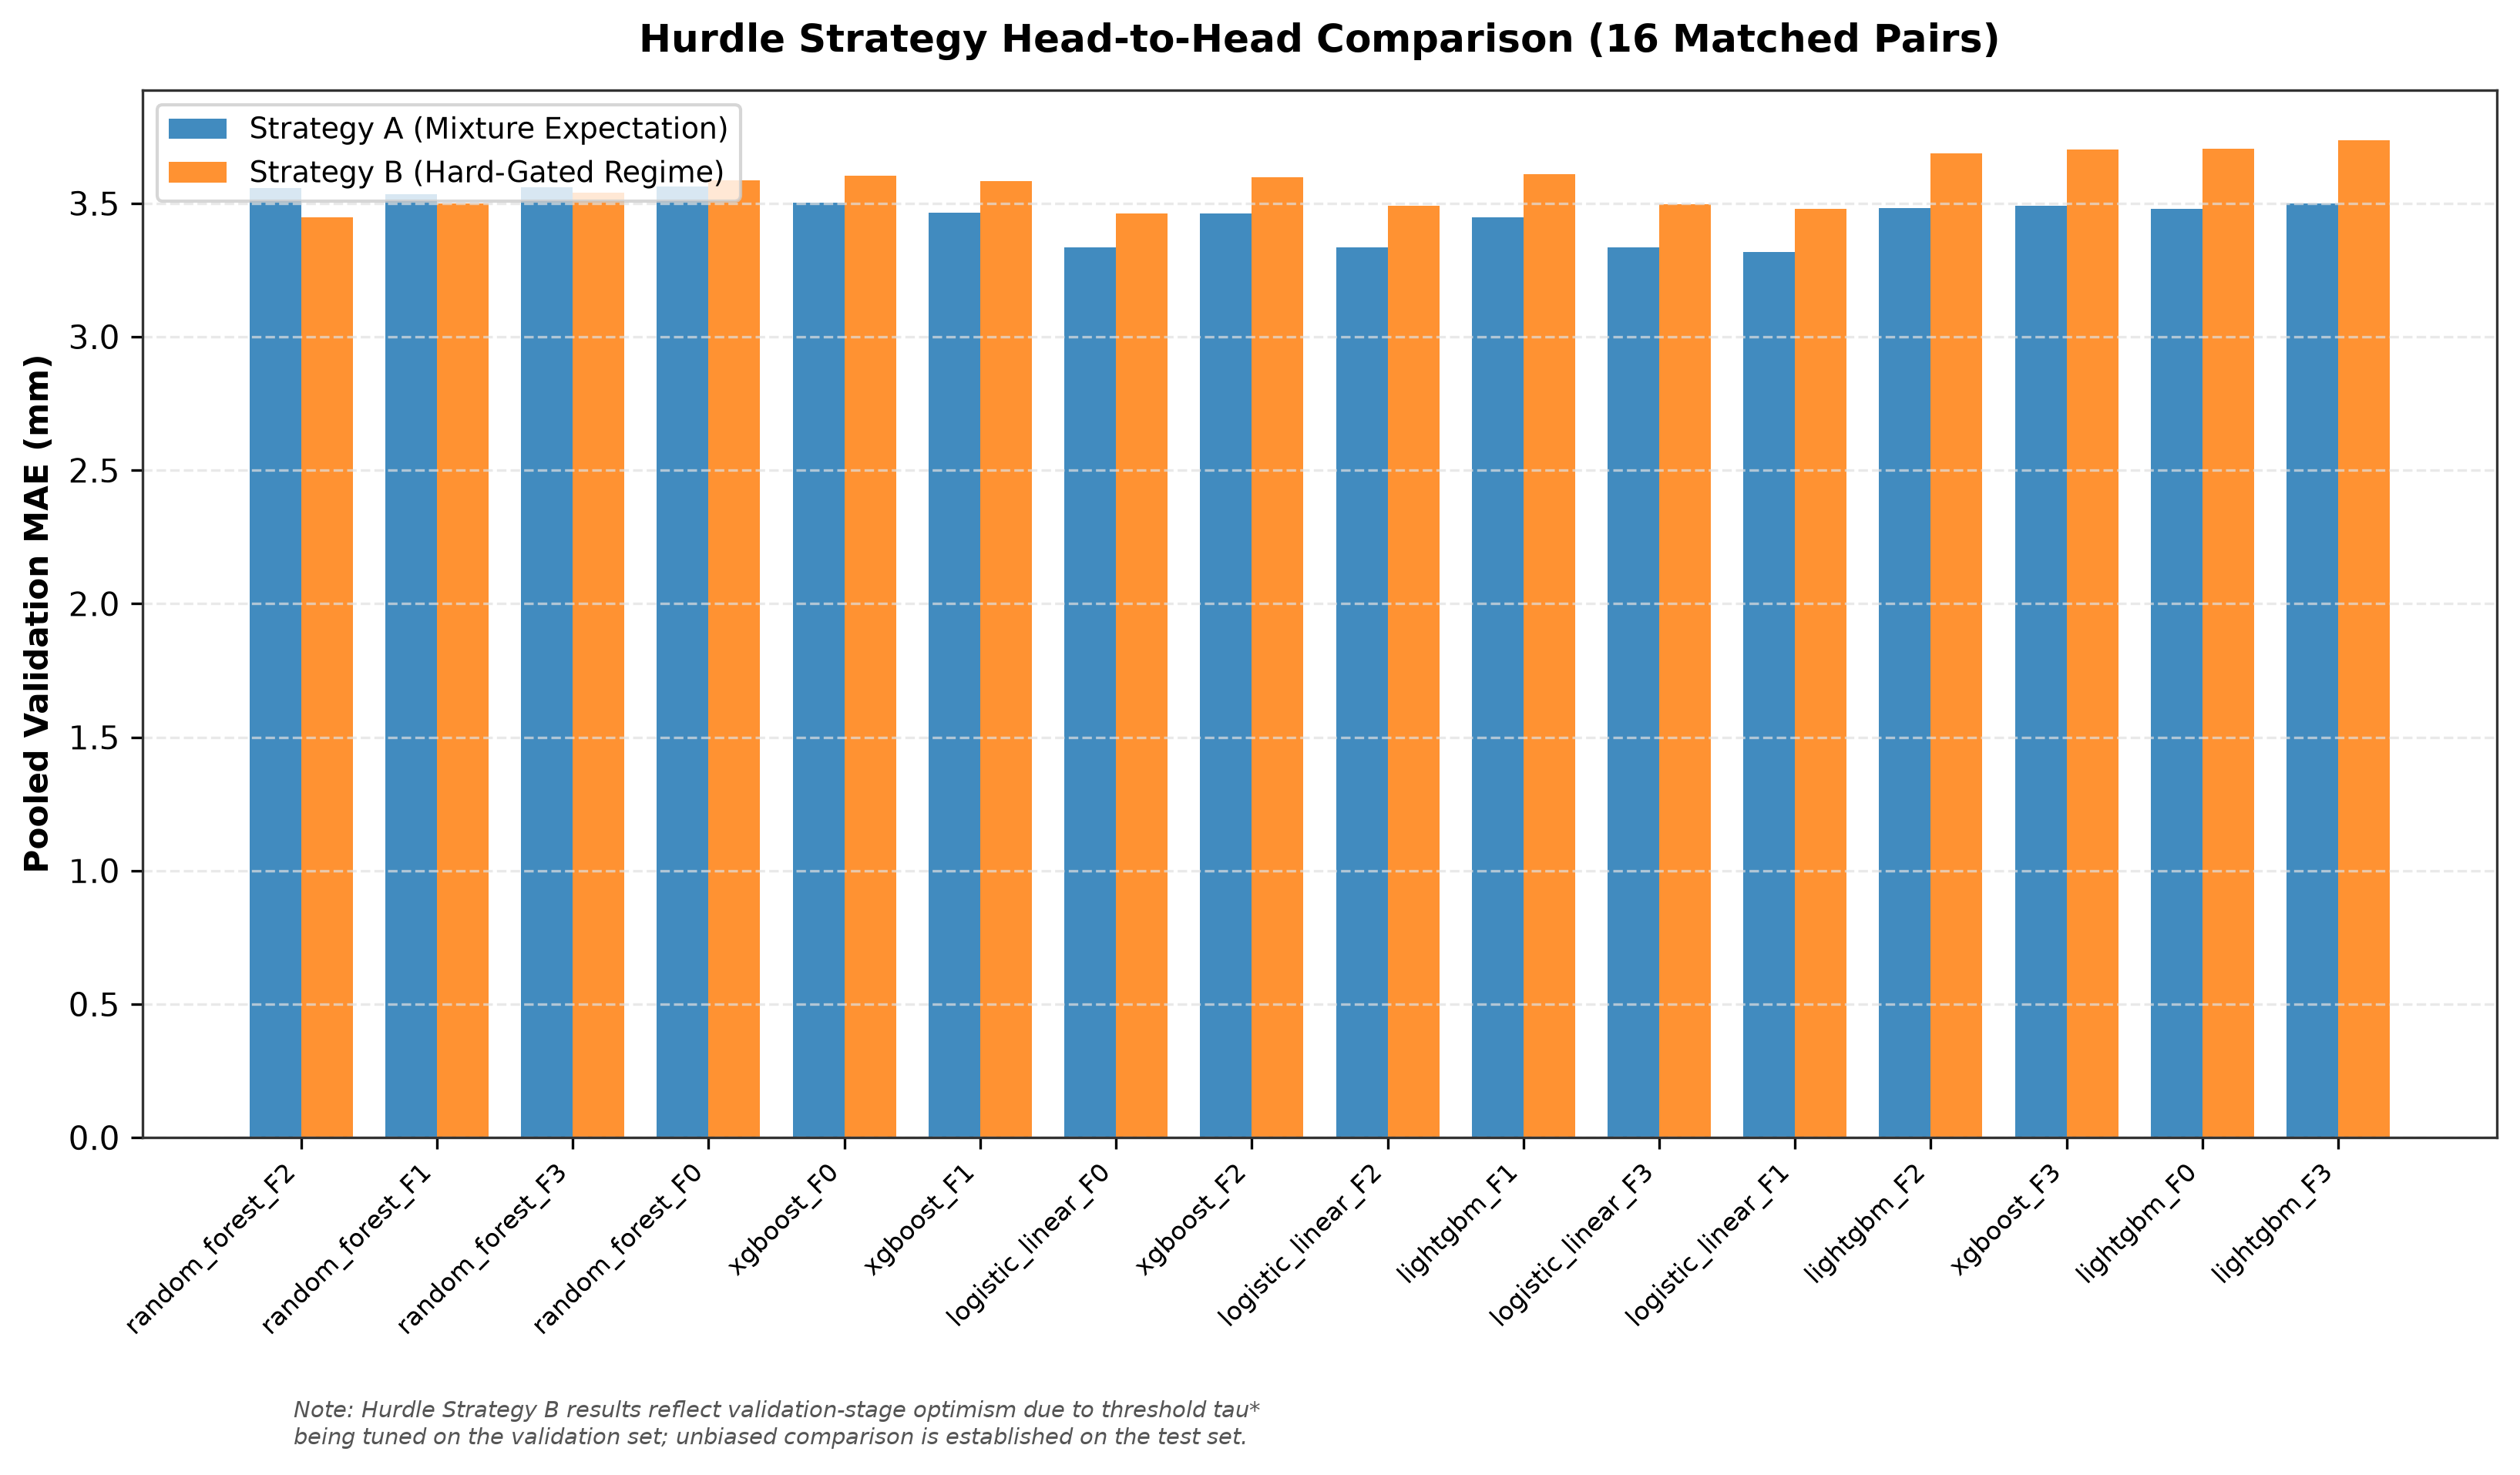

In [2]:
from src.analysis.loaders import load_all_validation_results
from src.analysis.aggregate import compute_hurdle_ablation
from src.analysis.plotting import plot_hurdle_ablation_comparison

df_results = load_all_validation_results()
df_hurdle = compute_hurdle_ablation(df_results)
display(df_hurdle)

fig = plot_hurdle_ablation_comparison(df_hurdle, save_name="fig04_hurdle_ablation.png")
